# k Nearest Neighbor (kNN)

## Fundamentos Teóricos

### ¿Qué es k Nearest Neighbor (kNN)?

* El algoritmo K-Nearest Neighbors (KNN) es un modelo de aprendizaje automático supervisado que se puede utilizar tanto para resolver problemas de clasificación como de regresión.   

* Es un algoritmo no paramétrico, lo que significa que no hace suposiciones, sino que construye el modelo enteramente a partir de los datos proporcionados.   

* Se le clasifica como un algoritmo de "aprendizaje perezoso" (lazy learner) o aprendizaje basado en memoria.

* Esto indica que no pasa por una etapa de entrenamiento formal en la que construye un modelo matemático previo, sino que almacena todo el conjunto de datos de entrenamiento y realiza los cálculos necesarios únicamente en el momento de hacer una predicción.   

* En el caso específico del cáncer de mama, el modelo kNN reduce un tumor a un punto o "patrón" matemático en un hiperespacio (como ${R}^5$ usando características como el radio, textura, perímetro, área y suavidad) para clasificar si un nuevo tumor es benigno o maligno basándose en los casos históricos.   

### Métricas de distancia y el valor $k$ vecinos en el kNN

#### Métricas de distancia
El algoritmo estima la similitud o proximidad entre los puntos de datos utilizando métricas de cálculo de distancia espacial.   

* **Distancia Euclidiana**: Es la distancia en línea recta entre dos puntos en el espacio euclidiano y es la más utilizada para medir qué tan parecidas son las muestras históricas frente a un nuevo patrón.   

$$
d(x,y) = \sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
$$

* **Distancia de Manhattan**: Representa la distancia calculada moviéndose únicamente en líneas rectas (como en una cuadrícula de calles de ciudad).

$$
d(x,y) = \sum_{i=1}^{n}|x_i-y_i|
$$

* **Distancia de Minkowski**: Es una fórmula general que, dependiendo del ajuste de un parámetro "$p$", puede actuar como distancia Euclidiana ($p = 2$) o de Manhattan ($p = 1$).

$$
d(x,y) = \left(\sum_{i=1}^{n}|x_i-y_i|^p\right)^{\frac{1}{p}}
$$

* Otras métricas: Incluyen la distancia del coseno (para vectores), distancia de Jaccard y distancia de Hamming (para datos categóricos).   

#### Importancia de "$k$"
* El valor "k" define cuántos vecinos cercanos se verificarán para determinar la clase de un nuevo punto de datos.   

* La elección del valor correcto de "k" se denomina ajuste de hiperparámetros.   Un valor de "k" muy pequeño (ej. k=1) puede hacer que el modelo sea demasiado sensible al ruido y a las variaciones menores, provocando un sobreajuste y una generalización deficiente.

* Un valor de "k" muy grande puede provocar un subajuste del modelo.

* Es importante tener en cuenta que al usar valores pares de "k" pueden ocurrir empates en las votaciones (ej. empate entre benigno y maligno para k=2), por lo que se debe ajustar con cuidado.

### Normalización / Escalamiento

Dado que kNN se basa en distancias, es obligatorio normalizar o escalar las características (ej. usando StandardScaler o MinMaxScaler) antes de "entrenar el modelo" (o sea calcular los vecinos).

Si no se normaliza, los atributos con escalas grandes (como el Área de un tumor, con valores mayores de $1000$) dominarán el cálculo de la distancia sobre los atributos de escalas pequeñas (como la Suavidad, con valores menores a $0.1$), sesgando el resultado.

Para cada característica $j$:

$$
z_{ij}
=
\frac{x_{ij}-\mu_j^{\mathrm{train}}}
{\sigma_j^{\mathrm{train}}}
$$

donde:

- $x_{ij}$ = es el valor original;
- $\mu_j^{\mathrm{train}}$ = es la media calculada con el conjunto "entrenamiento";
- $\sigma_j^{\mathrm{train}}$ = es la desviación estándar calculada con el conjunto "entrenamiento";
- $z_{ij}$ = es el valor estandarizado.


### ¿Por qué se necesita un algoritmo kNN?

* Se necesita porque ofrece una solución basada en una premisa lógica e intuitiva: para identificar a qué categoría pertenece algo, simplemente hay que observar cuáles son las características de sus vecinos más cercanos.

* Es un algoritmo que cumple con un excelente equilibrio entre tres aspectos críticos en la industria: facilidad de interpretación de los resultados, bajo tiempo de cálculo (al no requerir entrenamiento previo) y un buen poder predictivo.   

* A diferencia de otros clasificadores binarios que requieren esfuerzo adicional para adaptarse a múltiples categorías, kNN se adapta a problemas multiclase de forma nativa y sin complicaciones.  

### ¿Cómo funciona?

El clasificador KNN determina la clase de un punto de datos no observado mediante un mecanismo de votación mayoritaria.

El proceso sigue estos pasos:   

1. **Seleccionar el número k**: Se define la cantidad de vecinos (k) que el modelo considerará.
2. **Calcular la distancia**: Se mide la distancia matemática (frecuentemente la distancia euclidiana) entre el nuevo punto de datos (el tumor a diagnosticar) y todos los demás puntos almacenados en el conjunto de entrenamiento.   
3. **Encontrar los vecinos más cercanos**: Se ordenan las distancias calculadas de forma ascendente y se seleccionan las "k" distancias más pequeñas.
4. **Predicción mediante votación**: Se analizan las clases a las que pertenecen esos "k" vecinos. La clase que más se repita (Moda - la mayoría de votos) será la clase asignada al nuevo punto de datos. Si la mayoría de los vecinos cercanos son tumores malignos, el nuevo tumor se clasificará como maligno.


## Pipeline y descripción del problema

### Pipeline de Machine Learning (kNN)

$$
\text{Problema}
\rightarrow
\text{Datos}
\rightarrow
\text{Preprocesamiento}
\rightarrow
\text{Exploración de }k
\rightarrow
\text{KNN}
\rightarrow
\text{Predicción}
\rightarrow
\text{Evaluación}
$$

### Problema (descripción)


#### Clasificación de cáncer de mama con KNN

Como ejemplo de aplicación, realizaremos un clasificador KNN básico, como objetivo estudiar:
* Cómo influye el número de vecinos k en la clasificación.
* Cuáles son los vecinos más cercanos de una observación.
* Cómo se produce la votación de los vecinos más cercanos de una observación.
* ¿Qué ocurre si cambiamos el número de vecinos $k$?


Queremos clasificar cada observación como:

* $0$ = **Maligno**
* $1$  = **Benigno**

Trabajaremos con cinco características:

* mean_radius
* mean_texture
* mean_perimeter
* mean_area
* mean_smoothness

### Regla de desición: ¿Cómo se decide la clase a la que pertenece un nuevo dato observado? (Moda)

Una vez identificados los  k  vecinos más cercanos de una observación  x , KNN asigna la clase que aparece con mayor frecuencia entre esos vecinos.

Si definimos el conjunto de índices de los  k  vecinos más cercanos como:

$N_k(x)$

entonces las etiquetas correspondientes son: ${yi:i∈Nk(x)}$

La predicción de KNN puede expresarse mediante la moda:

$\hat{y}(x) = mode({yi:i∈Nk(x)})$

donde:

* $x$ :          es la nueva observación que queremos clasificar;
* $N_k(x)$ :     es el conjunto de los  k  vecinos más cercanos;
* $y_i$ :        es la clase del vecino  i ;
* $mode()$ :     devuelve la clase que aparece con mayor frecuencia;
* $\hat{y}(x)$ : es la clase predicha por KNN.

### Datos y Preprocesamiento (limpieza de dataset)

#### Datos
Cargamos el dataset de "scikit-learn" y librerias necesarias

In [ ]:
# Bibliotecas para manipulación y visualización
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Dataset
from sklearn.datasets import load_breast_cancer

# División de datos
from sklearn.model_selection import train_test_split

# Escalamiento
from sklearn.preprocessing import StandardScaler

# Clasificador KNN
from sklearn.neighbors import KNeighborsClassifier

# Evaluación
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Cargamos el dataset
cancer = load_breast_cancer(as_frame=True)

print("Clases del dataset:", cancer.target_names)
print("Número de observaciones:", cancer.data.shape[0])
print("Número total de características:", cancer.data.shape[1])

Clases del dataset: ['malignant' 'benign']
Número de observaciones: 569
Número total de características: 30


Seleccionamos únicamente las cinco características utilizadas en este ejercicio (radio medio, textura media, perímetro medio, área media, suavidad media).

* X: características utilizadas para clasificar.
* y: diagnóstico real (tumor maligno o no).

In [ ]:

# Seleccionamos las cinco características
X = cancer.data[
    [
        "mean radius",
        "mean texture",
        "mean perimeter",
        "mean area",
        "mean smoothness"
    ]
].copy()

# Renombramos las columnas para facilitar su lectura
X.columns = [
    "mean_radius",
    "mean_texture",
    "mean_perimeter",
    "mean_area",
    "mean_smoothness"
]

# Variable objetivo
y = cancer.target.copy()
y.name = "diagnosis"

# Tabla de visualización
df = X.copy()
df["diagnosis"] = y

df.head()


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0
1,20.57,17.77,132.90,1326.0,0.08474,0
2,19.69,21.25,130.00,1203.0,0.10960,0
3,11.42,20.38,77.58,386.1,0.14250,0
4,20.29,14.34,135.10,1297.0,0.10030,0


#### Procesamiento: calidad y estructura de los datos
Preprocesamos los datos para limpiarlos. Dataset libre de contradicciones.

En esta etapa podemos realizar las siguientes tareas:

* Revisar dimensiones del dataset para conocer el número de observaciones y variables.
* Inspeccionar los tipos de datos para comprobar si las variables son numéricas, categóricas o requieren conversión.
* Detectar valores faltantes con isna() o isnull().
* Detectar registros duplicados para evitar observaciones repetidas innecesariamente.
* Obtener estadísticas descriptivas mediante describe(), incluyendo media, desviación estándar, mínimos, máximos y cuartiles.
* Revisar la distribución de la variable objetivo para conocer cuántos casos malignos y benignos existen.
* Identificar valores atípicos o escalas muy diferentes entre características.
* Decidir si es necesario limpiar, transformar o eliminar información antes de construir el modelo.

In [ ]:
# Dimensiones del dataset
print("Dimensiones del dataset:")
print(df.shape)

# Tipos de datos
print("\nTipos de datos:")
print(df.dtypes)

# Valores faltantes por columna
print("\nValores faltantes:")
print(df.isna().sum())

# Número de registros duplicados
print("\nRegistros duplicados:")
print(df.duplicated().sum())

# Estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(df.describe())

# Distribución de las clases
print("\nDistribución de diagnósticos:")
print(df["diagnosis"].value_counts())

print("\nDistribución porcentual:")
print(df["diagnosis"].value_counts(normalize=True) * 100)

Dimensiones del dataset:
(569, 6)

Tipos de datos:
mean_radius        float64
mean_texture       float64
mean_perimeter     float64
mean_area          float64
mean_smoothness    float64
diagnosis            int64
dtype: object

Valores faltantes:
mean_radius        0
mean_texture       0
mean_perimeter     0
mean_area          0
mean_smoothness    0
diagnosis          0
dtype: int64

Registros duplicados:
0

Estadísticas descriptivas:


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,1.000000



Distribución de diagnósticos:
diagnosis
1    357
0    212
Name: count, dtype: int64

Distribución porcentual:
diagnosis
1    62.741652
0    37.258348
Name: proportion, dtype: float64


Primera vista del dataset "original" (solo graficaremos dos características de las vistas para analizar; por motivos practicos).

* eje X: mean_radius;
* eje Y: mean_texture.

Este gráfico es solamente una proyección 2D para facilitar la interpretación visual.

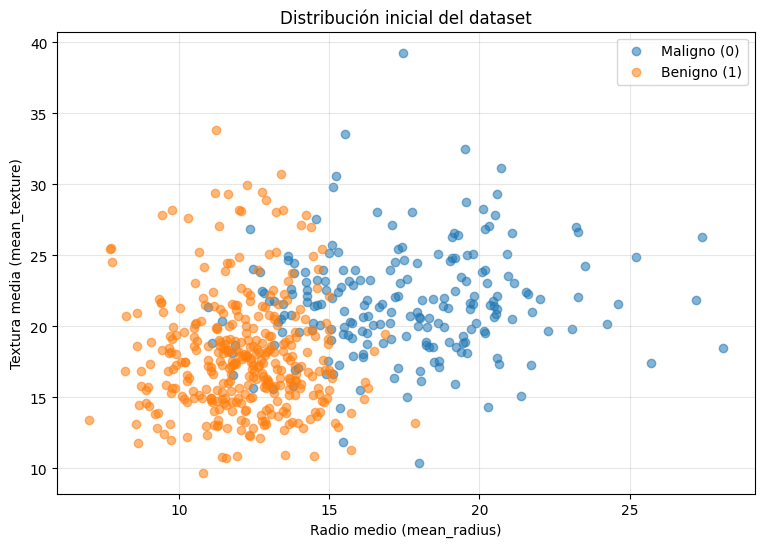

In [ ]:

plt.figure(figsize=(9, 6))

# Observaciones malignas
plt.scatter(
    X.loc[y == 0, "mean_radius"],
    X.loc[y == 0, "mean_texture"],
    alpha=0.55,
    label="Maligno (0)"
)

# Observaciones benignas
plt.scatter(
    X.loc[y == 1, "mean_radius"],
    X.loc[y == 1, "mean_texture"],
    alpha=0.55,
    label="Benigno (1)"
)

plt.title("Distribución inicial del dataset")
plt.xlabel("Radio medio (mean_radius)")
plt.ylabel("Textura media (mean_texture)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


División de dataset (entrenamiento y prueba)

Es muy necesario realizar "estratificación" (o sea dividir los datos de manera que se preserven las proporciones originales de las clases - entrenamiento/prueba) sobre el dataset antes de empezar a explorar $k$; pero, por ahora vamos a dividir el dataset de esta forma.

Aquí veremos que sucede al cambiar el hiperparámetro $k$ (numero de datos cercanos respecto a un dato nuevo sin clase asignada).


In [ ]:
# División del dataset (sin 'estratificación')
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (455, 5)
X_test : (114, 5)
y_train: (455,)
y_test : (114,)


Escalamos en función del conjunto de "entrenamiento" sin estratificación.

No olvidar que... para cada característica $j$:

$$
z_{ij}
=
\frac{x_{ij}-\mu_j^{\mathrm{train}}}
{\sigma_j^{\mathrm{train}}}
$$

In [ ]:

# Creamos/instanciamos el escalador
scaler = StandardScaler()

# Aprendemos media y desviación estándar únicamente con "entrenamiento" (sin estratificación)
X_train_scaled = scaler.fit_transform(X_train)

# Transformamos prueba utilizando los mismos parámetros, o sea media y desviación estándar antes calculada con .fit_transform (conjunto "prueba" sin estratificación)
X_test_scaled = scaler.transform(X_test)

print("Media aprendida:")
print(scaler.mean_)

print("\nDesviación estándar aprendida:")
print(scaler.scale_)


Media aprendida:
[1.41176352e+01 1.91850330e+01 9.18822418e+01 6.54377582e+02
 9.57440220e-02]

Desviación estándar aprendida:
[3.53192761e+00 4.26131404e+00 2.42952845e+01 3.54552925e+02
 1.39076981e-02]


#### Exploración de $k$

En la etapa anterior:
1. Limpiamos el dataset.
2. Dividimos en datos de entrenamiento y prueba sin estratificación.
3. Escalamos los datos, ya que este modelo se basa en definir distancias.

Ahora probaremos diferentes valores de $k$ (cantidad de vecinos que participarán en la votación) para observar cómo cambia el accuracy.

Vamos a definir $k = 5$ y en esta versión probaremos valores impares entre 1 - 29.

In [ ]:

# Valores de k que vamos a explorar (impares 1 - 29 para evitar empates en la votación)
valores_k = range(1, 30, 2)

# Lista para guardar el accuracy de cada valor de k
accuracies = []

for k in valores_k:

    # Creamos un clasificador KNN con el valor actual de k
    modelo = KNeighborsClassifier(n_neighbors=k)

    # Ajustamos KNN con entrenamiento (entrenamos con conjunto de entrenamiento previamente escalado)
    modelo.fit(X_train_scaled, y_train)

    # Clasificamos las observaciones de prueba
    predicciones = modelo.predict(X_test_scaled) # Aquí es en donde se hace el calculo de las distancias (realiza euclidiana)

    # Calculamos el accuracy
    accuracy_k = accuracy_score(y_test, predicciones)

    # Guardamos el resultado
    accuracies.append(accuracy_k)

# Mostramos los resultados en una tabla
tabla_k = pd.DataFrame({
    "k": list(valores_k),
    "accuracy": accuracies
})

tabla_k


,k,accuracy
0,1,0.929825
1,3,0.903509
2,5,0.929825
3,7,0.956140
4,9,0.956140
5,11,0.964912
6,13,0.956140
7,15,0.956140
8,17,0.956140
9,19,0.964912



#### Visualización: accuracy frente a $k$

La gráfica permite observar cómo cambia el desempeño del clasificador cuando modificamos el número de vecinos.


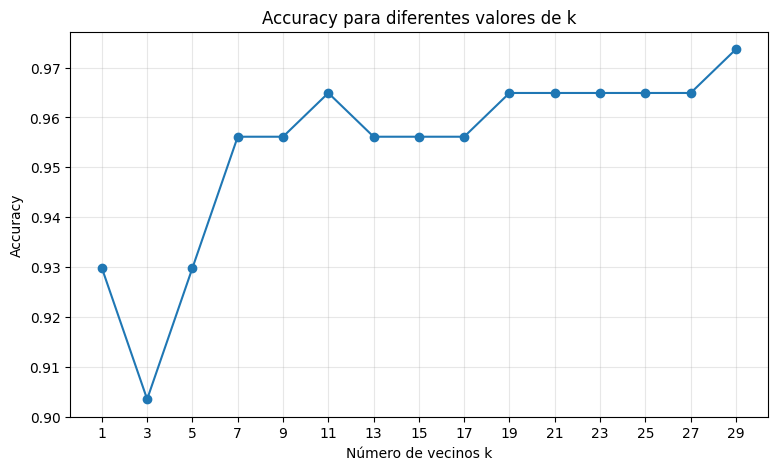

In [ ]:

plt.figure(figsize=(9, 5))

plt.plot(
    tabla_k["k"],
    tabla_k["accuracy"],
    marker="o"
)

plt.title("Accuracy para diferentes valores de k")
plt.xlabel("Número de vecinos k")
plt.ylabel("Accuracy")
plt.xticks(tabla_k["k"])
plt.grid(alpha=0.3)

plt.show()



#### Selección del valor de $k$

Para continuar con el ejercicio seleccionaremos el valor de $k$ que obtuvo el mayor accuracy en esta exploración.

Si varios valores empatan, elegiremos el menor.


In [ ]:
# Encontramos el mayor accuracy observado
mejor_accuracy = tabla_k["accuracy"].max()

# Seleccionamos el menor k entre los que obtuvieron ese accuracy
mejor_k = int(
    tabla_k.loc[
        tabla_k["accuracy"] == mejor_accuracy,
        "k"
    ].min() # nos aseguramos que sea el menor
)

print("Mejor k observado:", mejor_k)
print(f"Accuracy observado: {mejor_accuracy:.4f}")


Mejor k observado: 29
Accuracy observado: 0.9737



### kNN (Creación y ajuste del clasificador final)

Creamos nuevamente KNN con el valor seleccionado de $k$.

KNN es un método de **aprendizaje diferido**. `fit()` almacena los ejemplos de entrenamiento y prepara el estimador para buscar vecinos posteriormente.


In [ ]:
# Creamos el clasificador final con el valor seleccionado de k
knn = KNeighborsClassifier(n_neighbors=mejor_k)

# Ajustamos el clasificador con los datos de entrenamiento escalados
knn.fit(X_train_scaled, y_train)

print("Clasificador final creado con k =", mejor_k) # 29 vecinos cercanos


Clasificador final creado con k = 29



#### ¿Quiénes son los vecinos de una observación?

La distancia euclidiana puede escribirse como:

$$
d(\mathbf{x},\mathbf{x}_i)
=
\left(
\sum_{j=1}^{p}
(x_j-x_{ij})^2
\right)^{1/2}
$$

Ahora tomaremos la primera observación del conjunto de prueba y utilizaremos `kneighbors()` para visualizar:

- las distancias;
- los índices de sus vecinos;
- la clase de cada vecino.

Nota: La clave es usar `kneighbors()` para responder a esta pregunta.

In [ ]:

# Seleccionamos la primera observación del conjunto de prueba
x_consulta = X_test_scaled[0].reshape(1, -1)

# Buscamos sus vecinos más cercanos  (uso de )
distancias, indices = knn.kneighbors(
    x_consulta,
    n_neighbors=mejor_k
)

# Recuperamos las clases reales de esos vecinos
clases_vecinos = y_train.iloc[indices[0]].to_numpy()

# Construimos una tabla didáctica
vecinos = pd.DataFrame({
    "Distancia": distancias[0],
    "Clase": clases_vecinos,
    "Diagnóstico": [
        "Maligno" if clase == 0 else "Benigno"
        for clase in clases_vecinos
    ]
})

vecinos

,Distancia,Clase,Diagnóstico
0,0.368008,0,Maligno
1,0.379635,1,Benigno
2,0.384871,1,Benigno
3,0.424074,1,Benigno
4,0.431459,1,Benigno
5,0.457846,1,Benigno
6,0.511308,1,Benigno
7,0.511370,1,Benigno
8,0.515433,1,Benigno
9,0.523873,1,Benigno


### Predicción

Ahora clasificamos todas las observaciones de prueba.

In [ ]:

# Realizamos las predicciones
y_pred = knn.predict(X_test_scaled)

nombre_clase = {
    0: "Maligno",
    1: "Benigno"
}

# Mostramos las primeras 10 predicciones
resultados = pd.DataFrame({
    "Diagnóstico real": [
        nombre_clase[clase]
        for clase in y_test.to_numpy()
    ],
    "Diagnóstico predicho": [
        nombre_clase[clase]
        for clase in y_pred
    ]
})

resultados["Resultado"] = [
    "✅ Acierto" if real == pred else "❌ Error"
    for real, pred in zip(y_test.to_numpy(), y_pred)
]

resultados.head(10)


,Diagnóstico real,Diagnóstico predicho,Resultado
0,Benigno,Benigno,✅ Acierto
1,Maligno,Maligno,✅ Acierto
2,Maligno,Maligno,✅ Acierto
3,Benigno,Benigno,✅ Acierto
4,Benigno,Benigno,✅ Acierto
5,Maligno,Maligno,✅ Acierto
6,Maligno,Maligno,✅ Acierto
7,Maligno,Maligno,✅ Acierto
8,Benigno,Benigno,✅ Acierto
9,Benigno,Benigno,✅ Acierto


* `y_pred = knn.predict(X_test_scaled)`: El algoritmo evalúa los datos de prueba y clasifica cada observación, guardando todas sus respuestas en `y_pred`.   

* `nombre_clase = {...}`: Creamos un diccionario simple para traducir los resultados matemáticos a lenguaje natural. Convierte el número 0 en la palabra "Maligno" y el número 1 en "Benigno".   

* `pd.DataFrame({...}):` Tabla comparativa utilizando Pandas con dos columnas principales:   

  - "Diagnóstico real": Toma las respuestas verdaderas ocultas en tus datos de prueba (y_test.to_numpy()), las pasa por el diccionario y las coloca en la columna.
  - "Diagnóstico predicho": Hace lo mismo pero con las respuestas que el modelo acaba de calcular (y_pred).
  
* `resultados["Resultado"] = [...]`: Crea una tercera columna evaluativa. Utiliza la función zip para emparejar y recorrer al mismo tiempo la clase real y la clase predicha de cada observación. Si la predicción coincide con la realidad (real == pred): si son iguales, imprime "✅ Acierto"; de lo contrario, imprime "❌ Error".   

### Evaluación

Como en el nivel básico, utilizaremos únicamente:

1. matriz de confusión;
2. accuracy.

Las filas representan clases reales y las columnas clases predichas.

Orden utilizado:

- `0` = Maligno;
- `1` = Benigno.

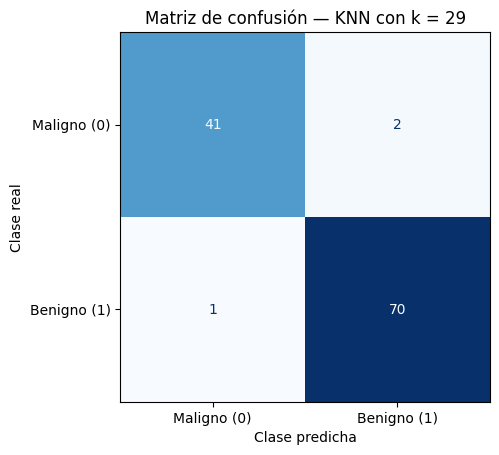

Accuracy: 0.9737
Accuracy: 97.37%


In [ ]:

# Matriz de confusión
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Maligno (0)", "Benigno (1)"]
)

disp.plot(cmap="Blues", colorbar=False)
plt.title(f"Matriz de confusión — KNN con k = {mejor_k}")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.show()

# Accuracy final
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")


#### Interpretación (matriz de confusión)

El modelo logra clasificar de forma correcta 41 casos malignos como malignos. El modelo predice como falso positivo un caso benigno; pero el modelo lo clasifica como maligno, cuando no es así.

El modelo logra clasificar de forma correcta 70 casos benignos como benignos; pero el modelo clasifica dos casos como malignos cuando no lo son.